# The AIR-SPACE time course: every analysis on six lymph nodes

AIR-SPACE (Jiang et al., *PNAS* 2026; GEO GSE286452) measured BCR and TCR molecules with their bead positions on mouse
popliteal lymph nodes before infection (Mock) and 3, 7, 10, 14 and 21 days after vaccinia infection: Curio Seeker
10 µm beads for the transcriptome, and nanopore reads that carry the V(D)J, the constant region, the bead barcode and a
UMI on one molecule.

This notebook runs every spaclone analysis on all six nodes with the package defaults and shows each figure:

1. the trust report of each node;
2. class-switch (CSR) and mutation (SHM) hotspots, the hotspot atlas and the isotype maps;
3. sciCSR's class-switch potential and its transition flow on the tissue, with the flux test;
4. transcriptome regions, clone maps and the scirpy maps;
5. the repertoire across the six days, and Threadfin clone states;
6. one table of the key numbers per day.

Nothing is tuned: each call is the default one, so the figures are what the package gives on these data.

In [1]:
import warnings
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats

import spaclone
from spaclone import bcr, gex, io, pl, pp, tl
from spaclone.ext import scirpy as sx
from spaclone.ext import threadfin

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 72
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 85})  # JPEG figures keep this long notebook small
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"  # one-line warnings
print("spaclone", spaclone.__version__)
print(" | ".join(f"{p} {version(p)}" for p in ("numpy", "pandas", "scipy", "anndata", "scanpy", "scirpy", "threadfin",
                                                "matplotlib")))

spaclone 1.0.1
numpy 2.5.4 | pandas 3.1.0 | scipy 1.18.1 | anndata 0.13.4 | scanpy 1.12.5 | scirpy 0.25.1 | threadfin 4.6.0 | matplotlib 3.11.2


## The data

All six nodes are built into `spaclone.datasets`: `spaclone.datasets.airspace(day)` downloads the bead counts and the
MiXCR clone table of a node from GEO once (69–105 MB per node; needs `pip install "spaclone[datasets]"`), checks their
sha256 and returns the two paths; files go to the user cache or to the folder in the environment variable
`SPACLONE_DATA_DIR`. `io.read_airspace` collapses reads into molecules (bead, UMI, chain), converts positions to µm and
keeps MiXCR's V alignments (`alignments=True`) for the mutation calls.

In [2]:
DAYS = ["Mock", "D3", "D7", "D10", "D14", "D21"]
data = {day: io.read_airspace(*spaclone.datasets.airspace(day), alignments=True) for day in DAYS}
pd.DataFrame({day: {"beads": sa.meta["n_beads"], "tissue beads": sa.meta["n_tissue_beads"], "reads": sa.meta["n_reads"],
                    "molecules": sa.meta["n_records"]} | sa.meta["records_by_locus"] for day, sa in data.items()}).T

,beads,tissue beads,reads,molecules,IGH,IGK,IGL,NA,TRA,TRB
Mock,78205.0,16642.0,14128.0,12054.0,797.0,7266.0,2677.0,12.0,280.0,1022.0
D3,78462.0,25118.0,24537.0,21047.0,1326.0,12785.0,4057.0,11.0,575.0,2293.0
D7,77245.0,26848.0,19700.0,18720.0,4043.0,12524.0,1109.0,2.0,181.0,861.0
D10,78558.0,34159.0,38920.0,32792.0,9180.0,16433.0,4900.0,2.0,402.0,1875.0
D14,78224.0,21477.0,28268.0,25504.0,2185.0,19798.0,2521.0,NaN,123.0,877.0
D21,79423.0,23040.0,18063.0,17173.0,3185.0,11263.0,1584.0,NaN,273.0,868.0


A few objects reused below: the tissue beads of each node, its germinal centres and plasma-cell area called from
the transcriptome (`gex.call_regions`), the filtered molecules on tissue, and one helper that draws one panel per
day.

In [3]:
tissue, regions, records = {}, {}, {}
for day, sa in data.items():
    g = sa.gex.copy()
    gex.call_regions(g, kind="germinal_centre")
    gex.call_regions(g, kind="plasma_cell")
    regions[day] = g[g.obs["in_tissue"].to_numpy(bool)].copy()
    xy = regions[day].obsm["spatial"]
    tissue[day] = pd.DataFrame({"x_um": xy[:, 0], "y_um": xy[:, 1]})
    records[day] = pp.filter_records(sa.air, valid_junction=True, productive=True, on_tissue=True).air


def by_day(draw, title, size=5.0):
    """One panel per day (``draw(day, ax)``), two rows of three, on the dark house surface."""
    fig, axes = plt.subplots(2, 3, figsize=(3 * size, 2 * size + 0.6), layout="constrained")
    fig.set_facecolor("black")
    for ax, day in zip(axes.flat, DAYS):
        draw(day, ax)
        ax.set_title(day, color="0.9", fontsize=12, loc="right")
    fig.suptitle(title, color="0.9", fontsize=13)
    plt.show()


pd.DataFrame({day: g.obs["region"].astype(str).value_counts() for day, g in regions.items()}).T.fillna(0).astype(int)

region,ASC,GC,other
Mock,1333,69,15240
D3,1927,469,22722
D7,2148,641,24059
D10,2730,3168,28261
D14,1711,2081,17685
D21,1813,1987,19240


## 1. Can the positions be trusted?

`spaclone.run` filters the molecules and runs every location-trust test the data allow, with its defaults. The status
of each node's verdicts (`report.status`; the sentences are in `report.verdict_molecule` and `report.verdict_clone`):

In [4]:
reports = {day: spaclone.run(sa) for day, sa in data.items()}
pd.DataFrame({day: r.status for day, r in reports.items()}).T

,overall,molecule,clone
Mock,clone_positions,not tested,signal
D3,clone_positions,not tested,signal
D7,clone_positions,not tested,signal
D10,clone_positions,not tested,signal
D14,clone_positions,not tested,signal
D21,clone_positions,not tested,signal


The trust report of the uninfected node (Mock):

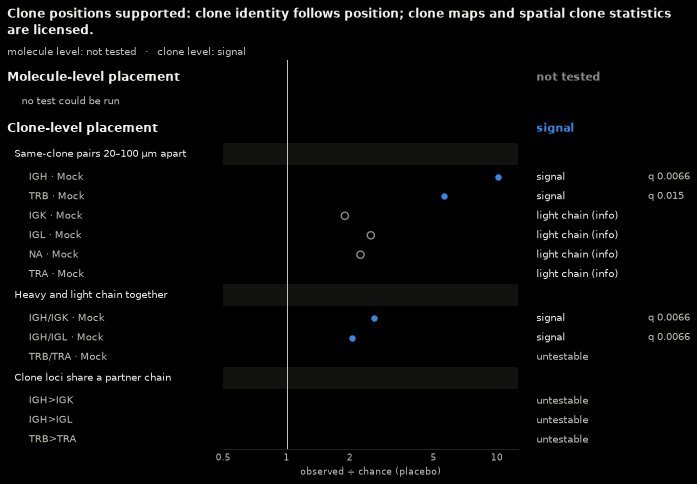

In [5]:
fig = reports["Mock"].plot()
plt.show()

The trust report of day 3:

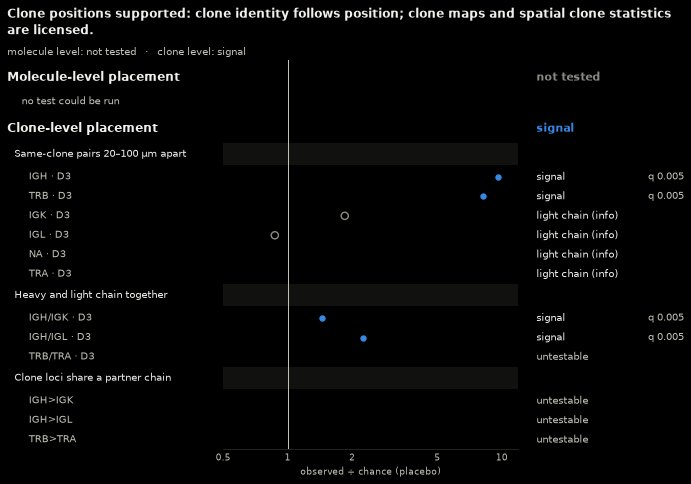

In [6]:
fig = reports["D3"].plot()
plt.show()

The trust report of day 7:

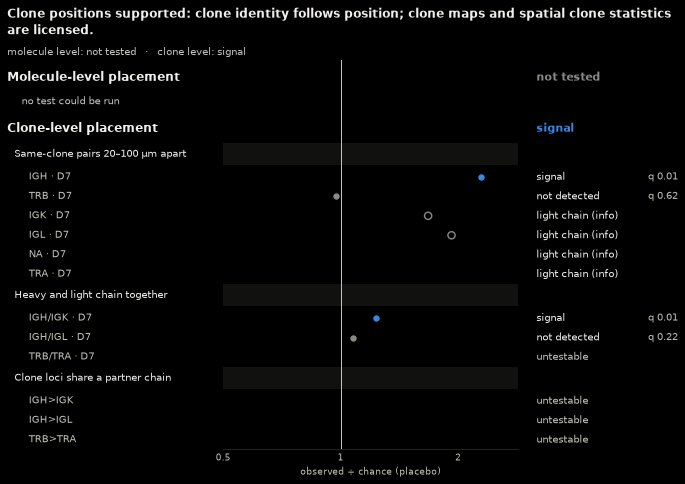

In [7]:
fig = reports["D7"].plot()
plt.show()

The trust report of day 10:

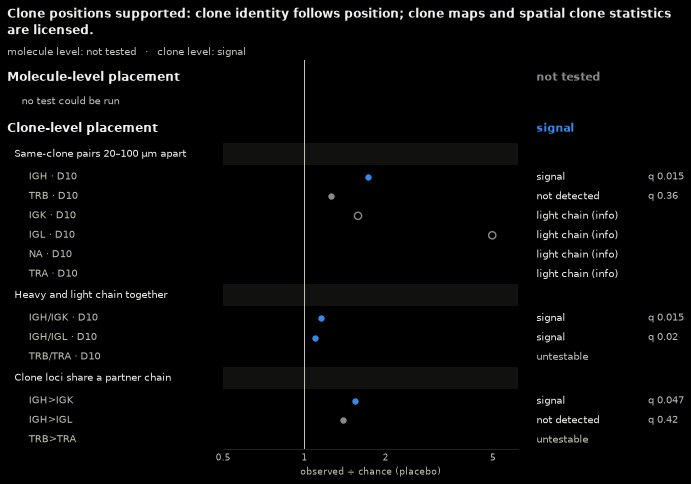

In [8]:
fig = reports["D10"].plot()
plt.show()

The trust report of day 14:

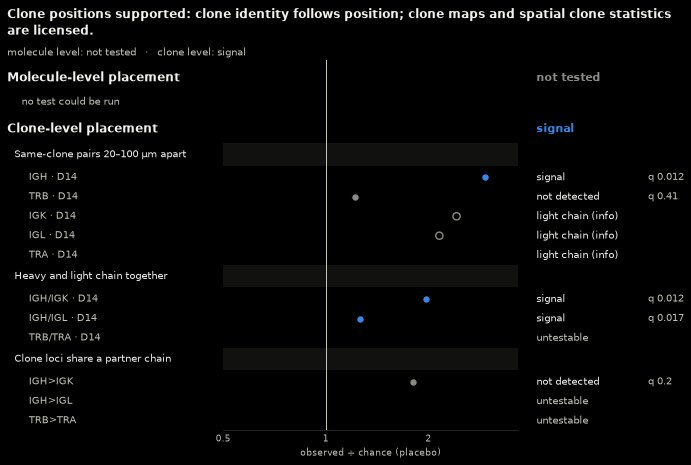

In [9]:
fig = reports["D14"].plot()
plt.show()

The trust report of day 21:

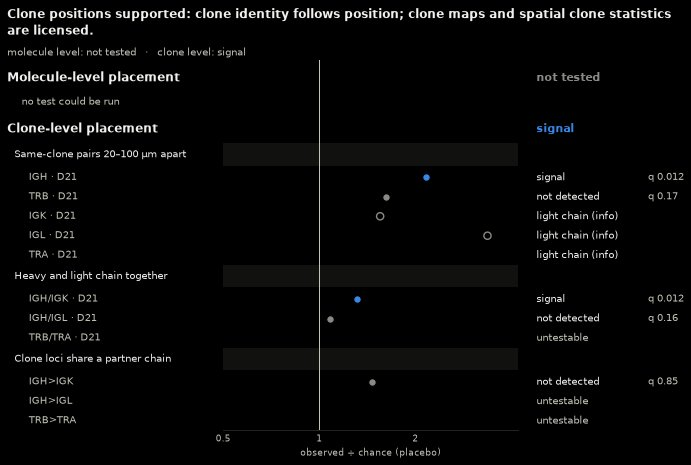

In [10]:
fig = reports["D21"].plot()
plt.show()

## 2. Class switching and mutation in space

`bcr.hotspot_workflow` merges heavy-chain molecules into loci (about one cell), maps the switched and the mutated share
with family-wise hotspots, finds the regions where CSR and SHM hotspots overlap (or, when there is none, takes each CSR
hotspot as a region) and reads each region's transcriptome identity.

In [11]:
hot = {day: bcr.hotspot_workflow(sa) for day, sa in data.items()}
for day, h in hot.items():
    print(f"{day}: {h!r}")

Mock: HotspotWorkflowResult(785 IGH records, 640 loci; 1 CSR and 0 SHM hotspots; 1 regions from CSR hotspots: 1: erythroid / plasmablast/ASC (mixed) (clone-level p CSR 0.996, SHM q 0.665))
D3: HotspotWorkflowResult(1,315 IGH records, 1,095 loci; 2 CSR and 0 SHM hotspots; 2 regions from CSR hotspots: 1: myeloid / plasmablast/ASC (mixed) (clone-level p CSR 0.35, SHM q 0.941); 2: plasma cell (clone-level p CSR 1, SHM q 0.941))
D7: HotspotWorkflowResult(4,016 IGH records, 3,656 loci; 0 CSR and 0 SHM hotspots; 0 CSR∩SHM regions)
D10: HotspotWorkflowResult(9,109 IGH records, 8,564 loci; 1 CSR and 0 SHM hotspots; 1 regions from CSR hotspots: 1: GC B (clone-level p CSR 0.011, SHM q 0.35))
D14: HotspotWorkflowResult(2,158 IGH records, 1,544 loci; 1 CSR and 0 SHM hotspots; 1 regions from CSR hotspots: 1: plasmablast/ASC / plasma cell (mixed) (clone-level p CSR 0.000999, SHM q 0.801))
D21: HotspotWorkflowResult(3,166 IGH records, 2,791 loci; 3 CSR and 0 SHM hotspots; 3 regions from CSR hotspots: 

The switched-share (CSR) and mutated-share (SHM) maps of all six nodes, with their hotspots and region windows:

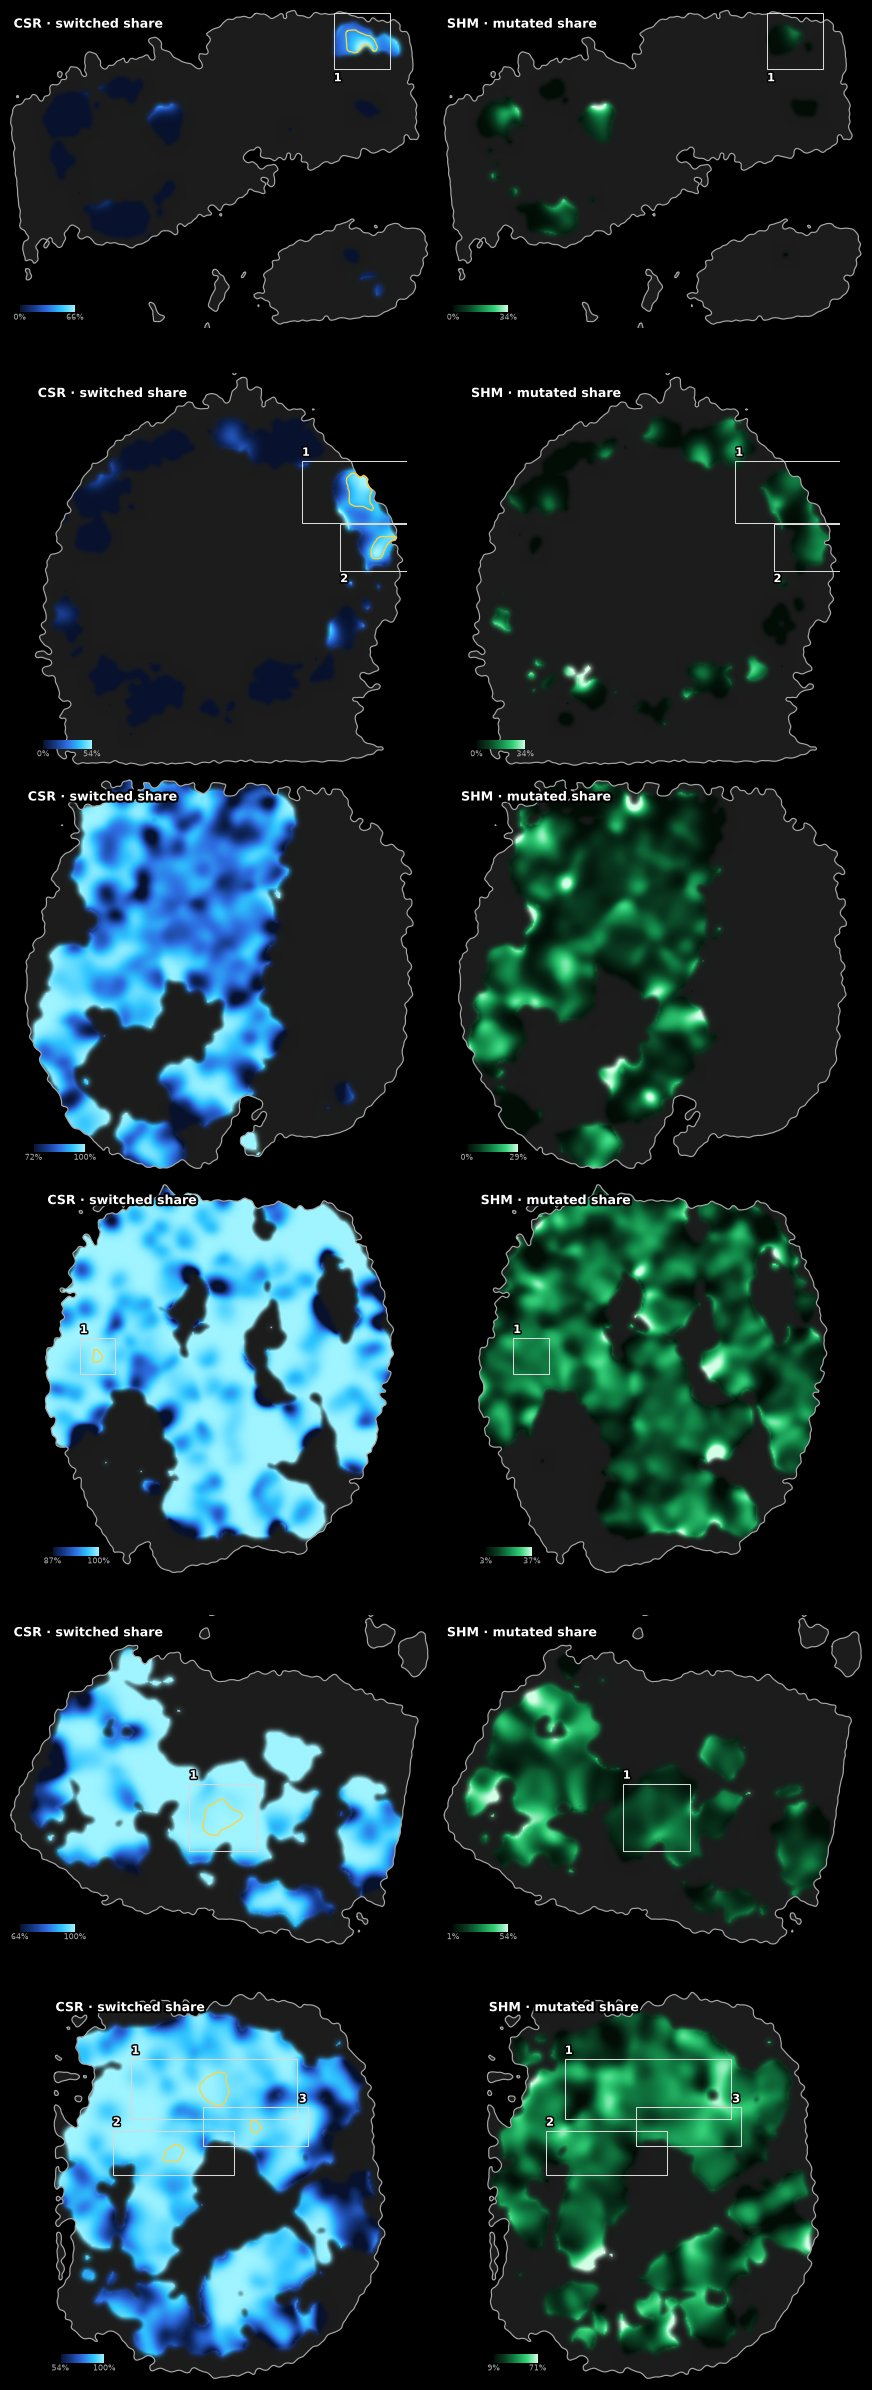

In [12]:
fig, axes = plt.subplots(len(DAYS), 2, figsize=(12, 5.6 * len(DAYS)), layout="constrained")
fig.set_facecolor("black")
for row, day in zip(axes, DAYS):
    pl.hotspot_overview(hot[day], axes=row, legend=False)
    row[0].set_ylabel(day, color="0.9", fontsize=14)
plt.show()

The hotspot atlas of the uninfected node (Mock): the maps, the hotspots and a zoom on each region with its transcriptome identity.

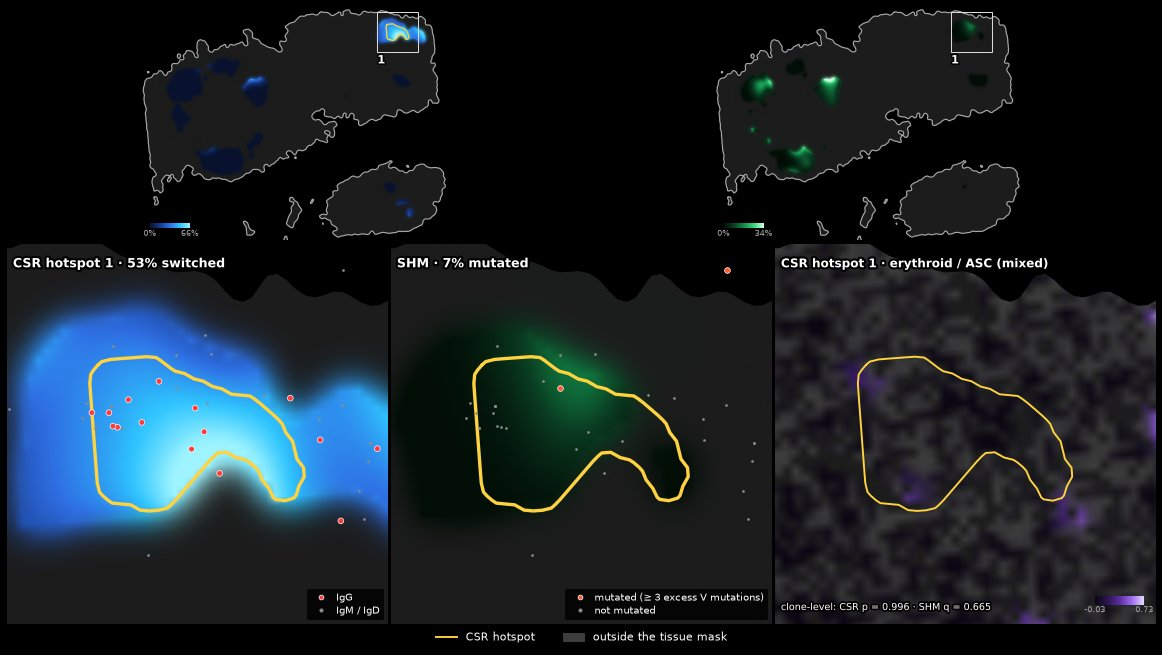

In [13]:
fig = pl.hotspot_atlas(hot["Mock"], dpi=72)
plt.show()

The hotspot atlas of day 3: the maps, the hotspots and a zoom on each region with its transcriptome identity.

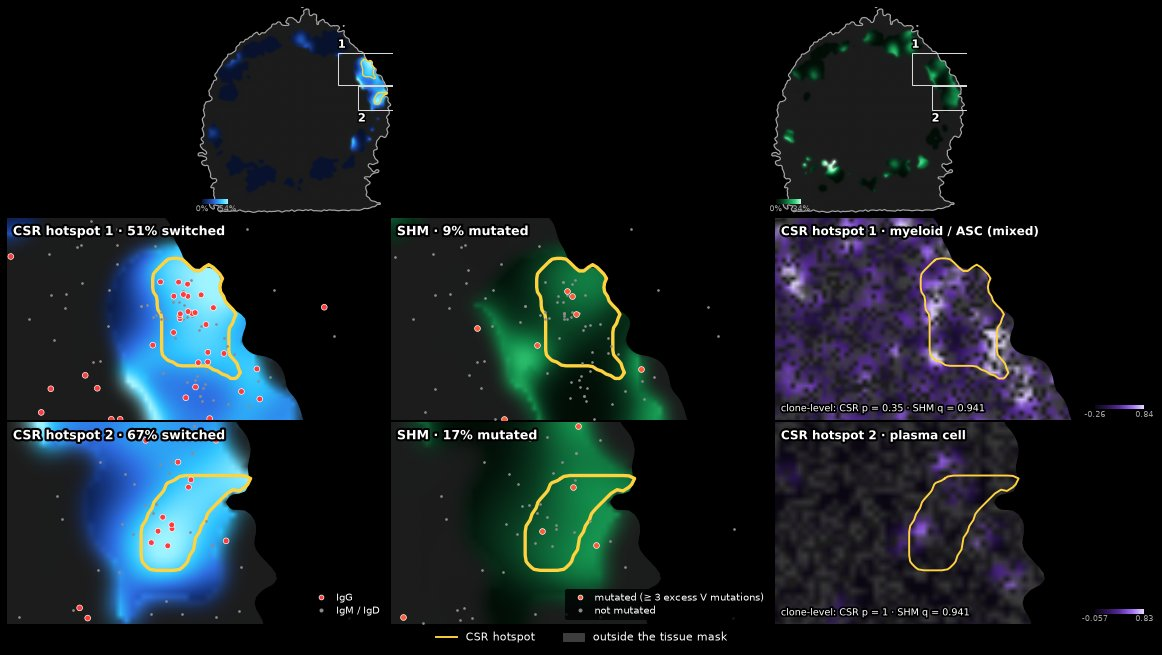

In [14]:
fig = pl.hotspot_atlas(hot["D3"], dpi=72)
plt.show()

The hotspot atlas of day 7: the maps, the hotspots and a zoom on each region with its transcriptome identity.

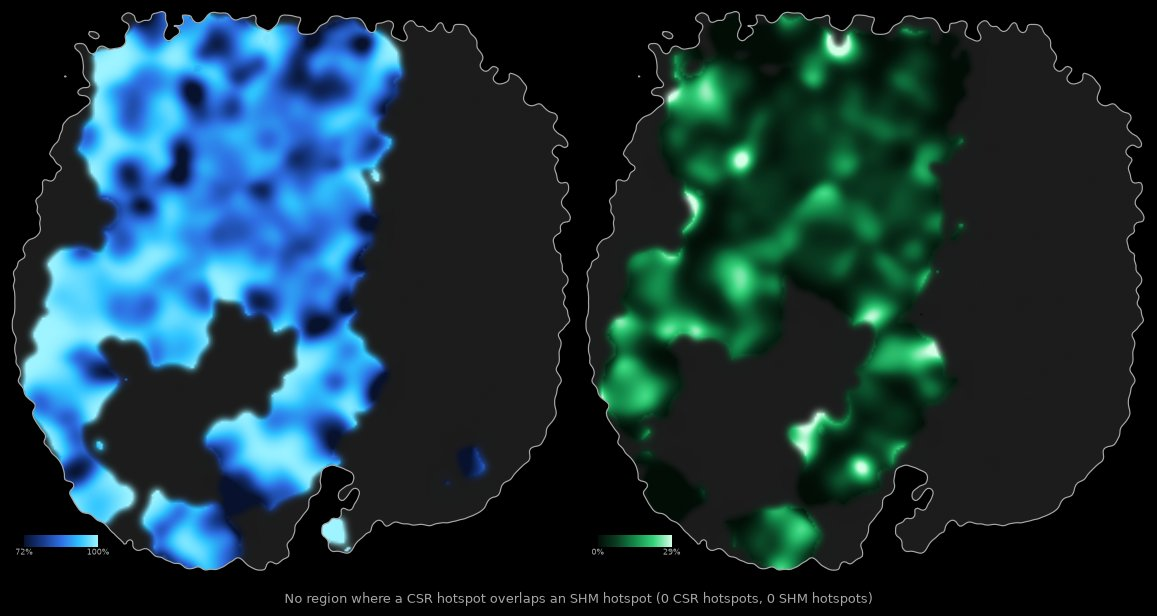

In [15]:
fig = pl.hotspot_atlas(hot["D7"], dpi=72)
plt.show()

The hotspot atlas of day 10: the maps, the hotspots and a zoom on each region with its transcriptome identity.

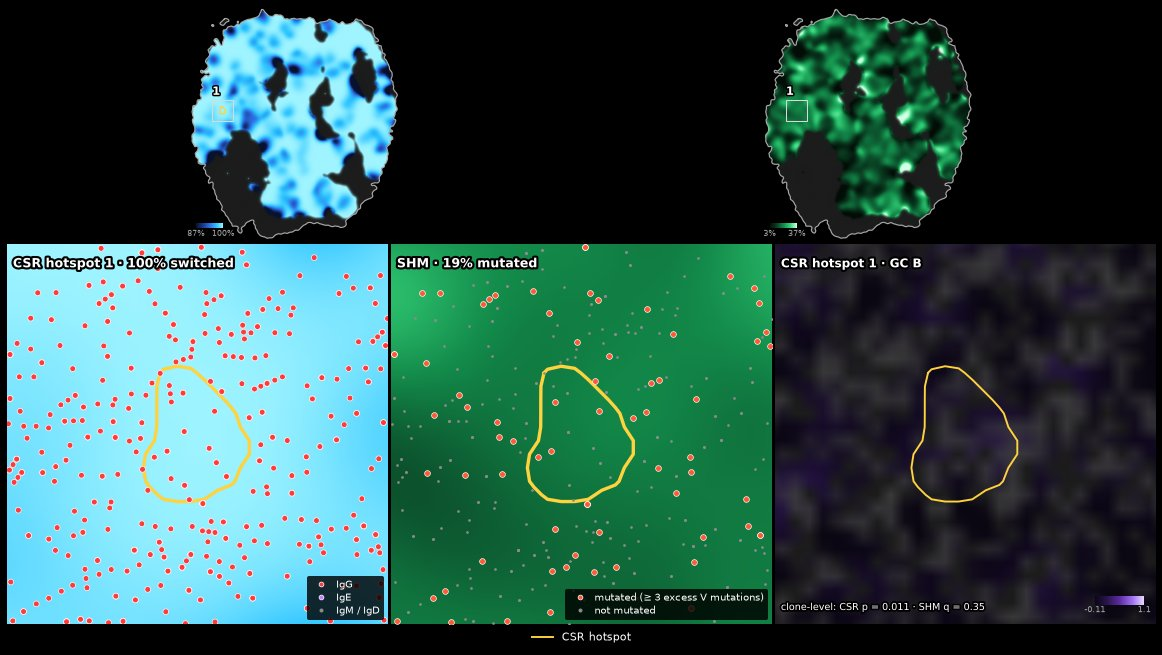

In [16]:
fig = pl.hotspot_atlas(hot["D10"], dpi=72)
plt.show()

The hotspot atlas of day 14: the maps, the hotspots and a zoom on each region with its transcriptome identity.

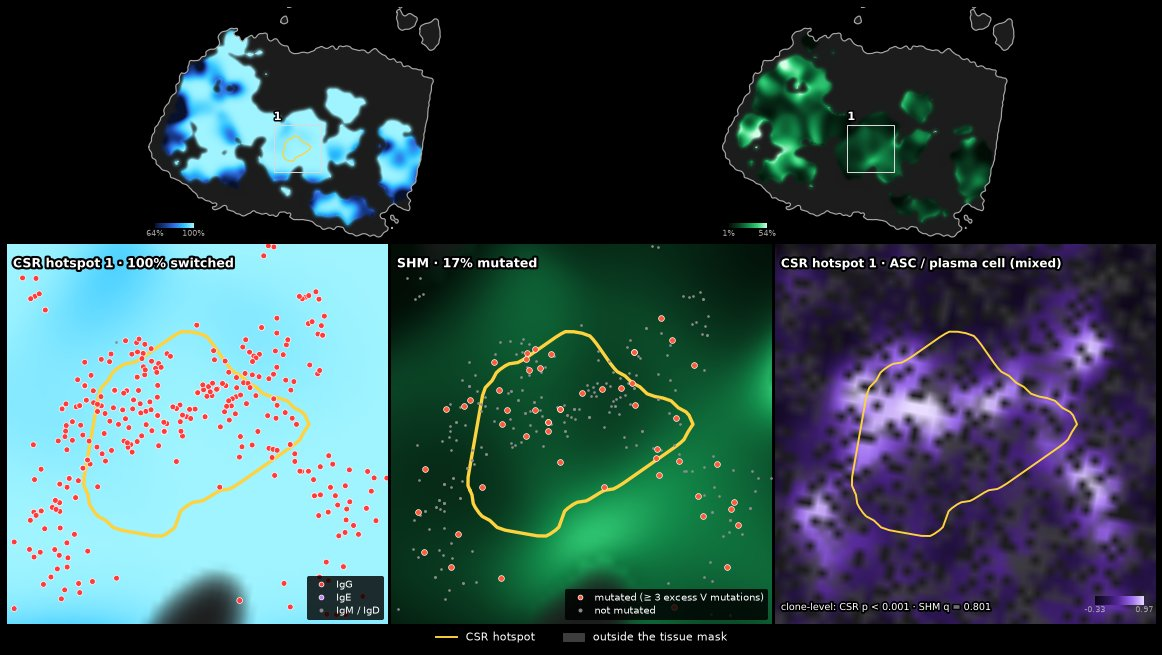

In [17]:
fig = pl.hotspot_atlas(hot["D14"], dpi=72)
plt.show()

The hotspot atlas of day 21: the maps, the hotspots and a zoom on each region with its transcriptome identity.

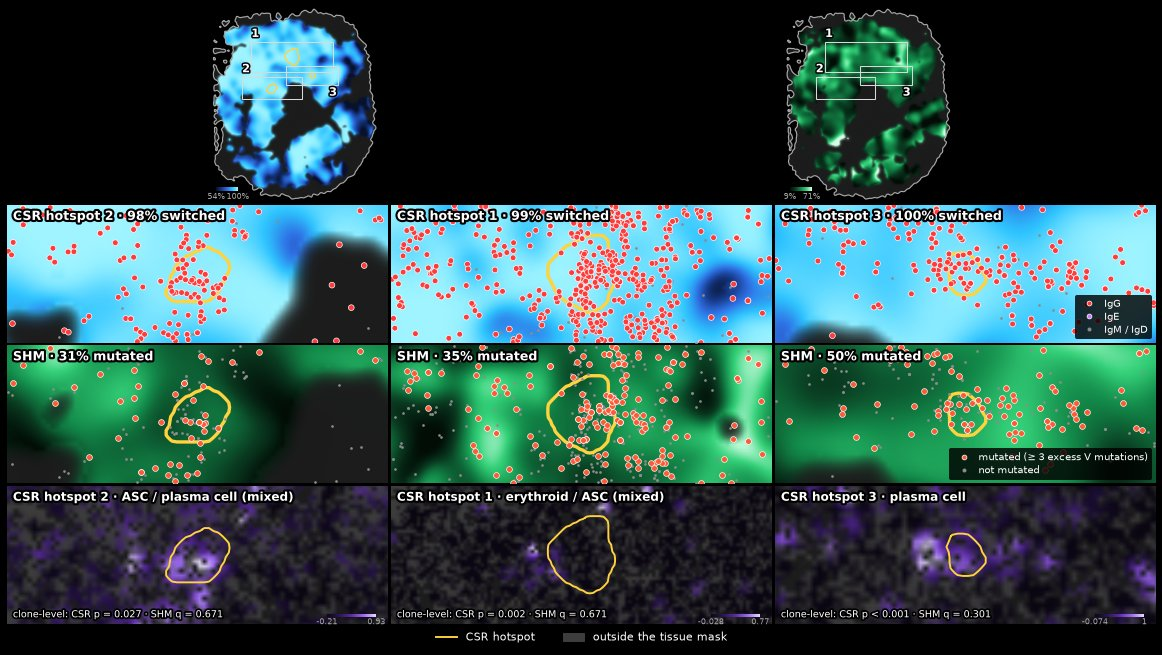

In [18]:
fig = pl.hotspot_atlas(hot["D21"], dpi=72)
plt.show()

Isotypes along the IgH locus and the class switches within clones, the uninfected node (Mock):

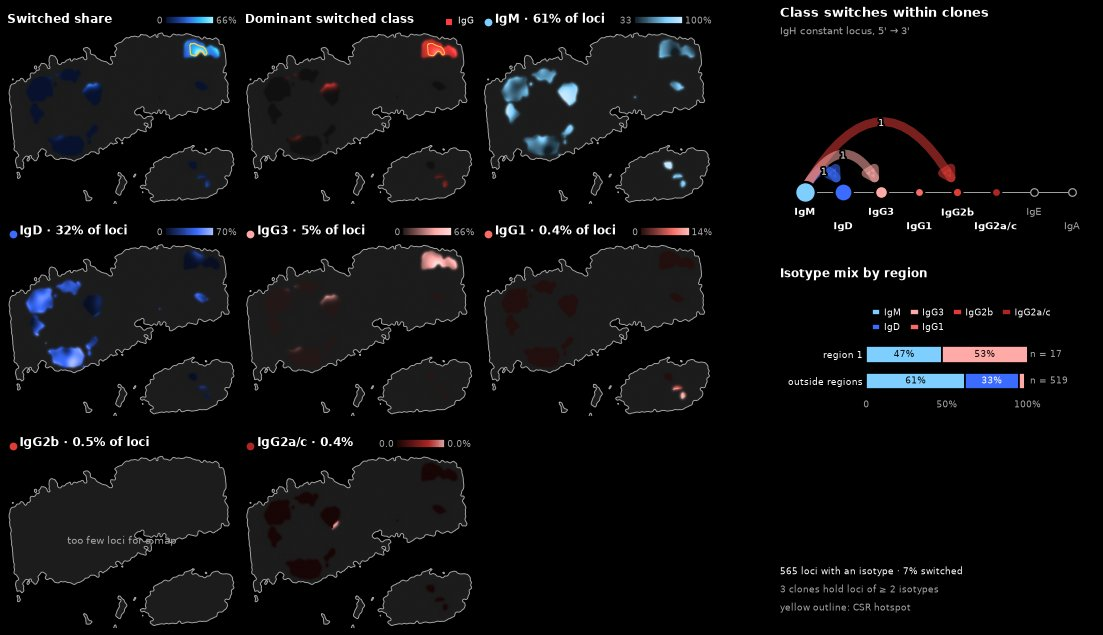

In [19]:
fig = pl.csr_map(hot["Mock"], dpi=72)
plt.show()

Isotypes along the IgH locus and the class switches within clones, day 3:

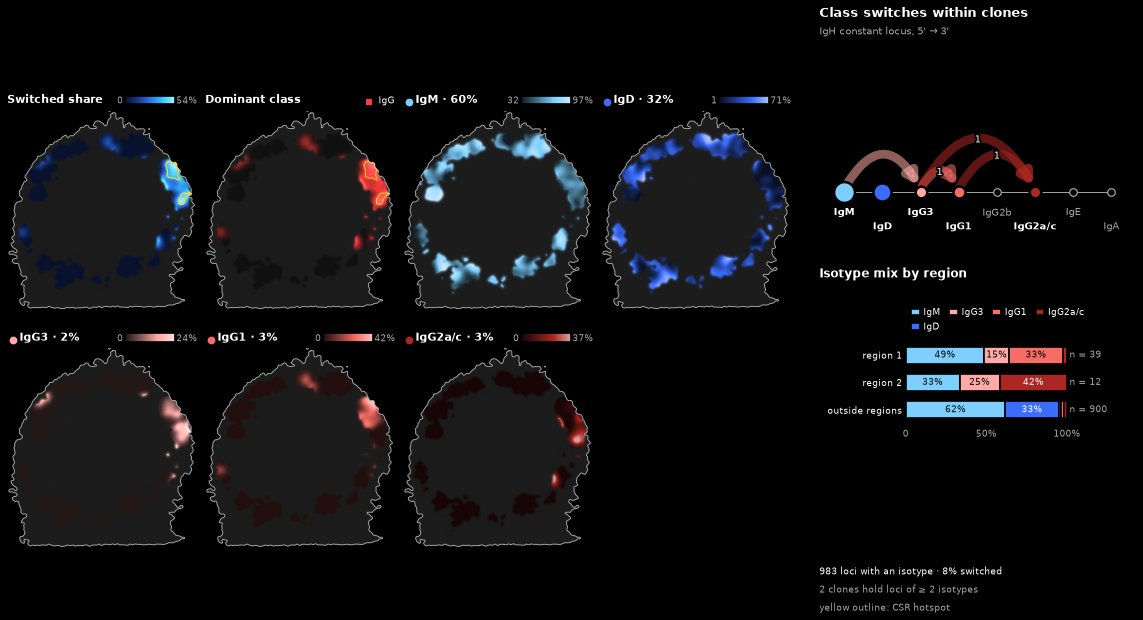

In [20]:
fig = pl.csr_map(hot["D3"], dpi=72)
plt.show()

Isotypes along the IgH locus and the class switches within clones, day 7:

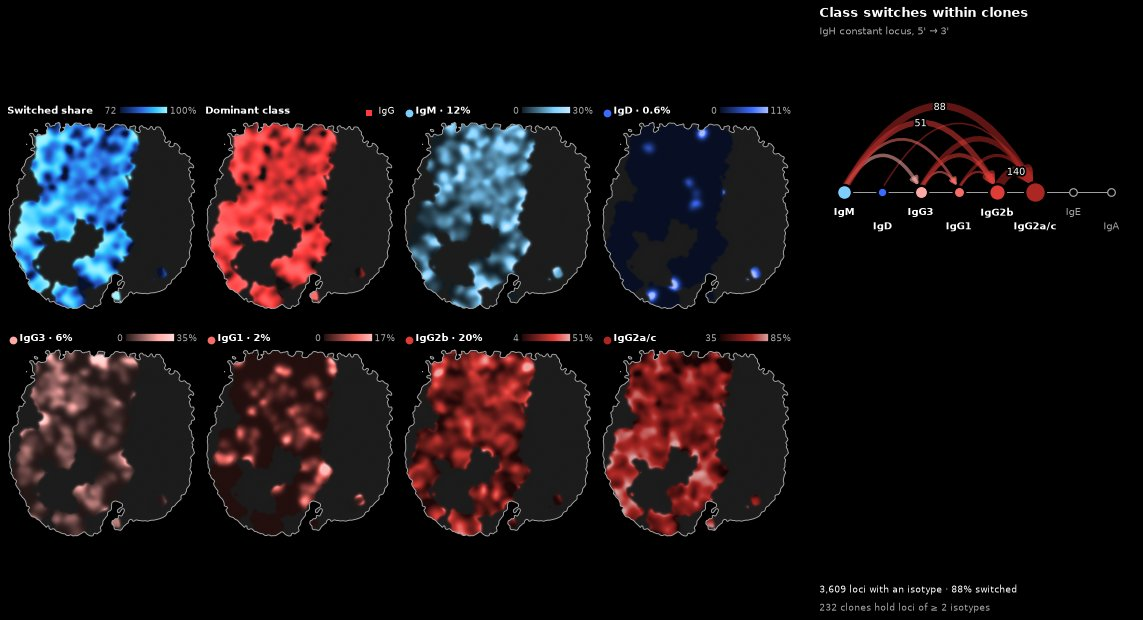

In [21]:
fig = pl.csr_map(hot["D7"], dpi=72)
plt.show()

Isotypes along the IgH locus and the class switches within clones, day 10:

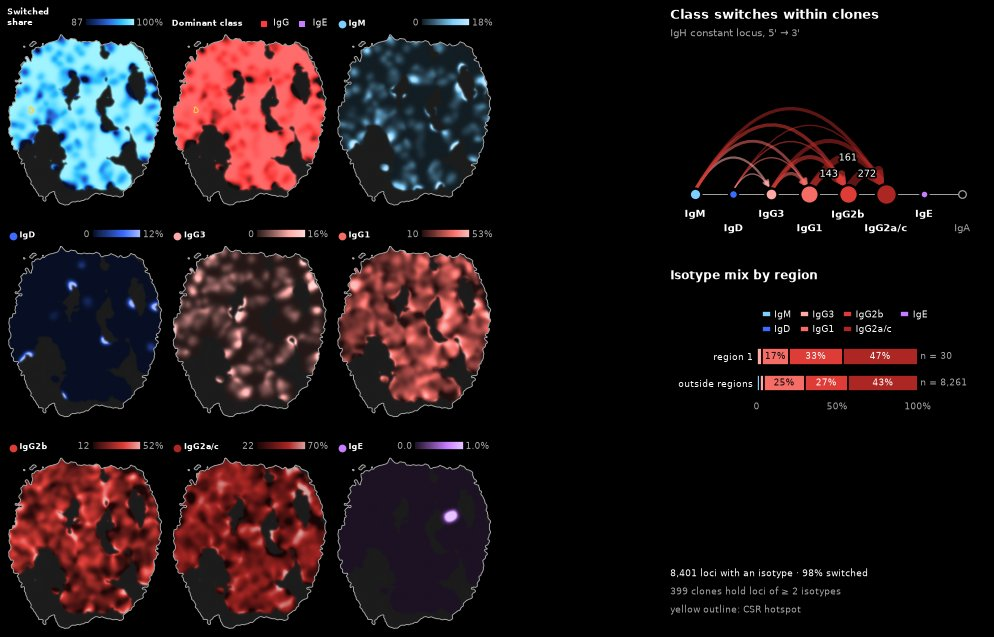

In [22]:
fig = pl.csr_map(hot["D10"], dpi=72)
plt.show()

Isotypes along the IgH locus and the class switches within clones, day 14:

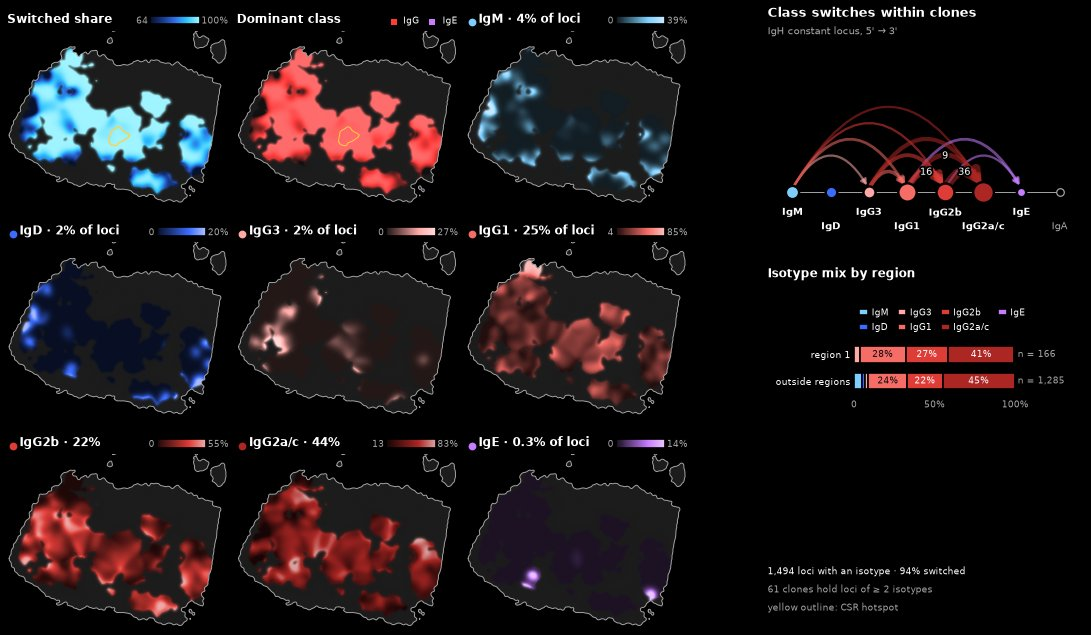

In [23]:
fig = pl.csr_map(hot["D14"], dpi=72)
plt.show()

Isotypes along the IgH locus and the class switches within clones, day 21:

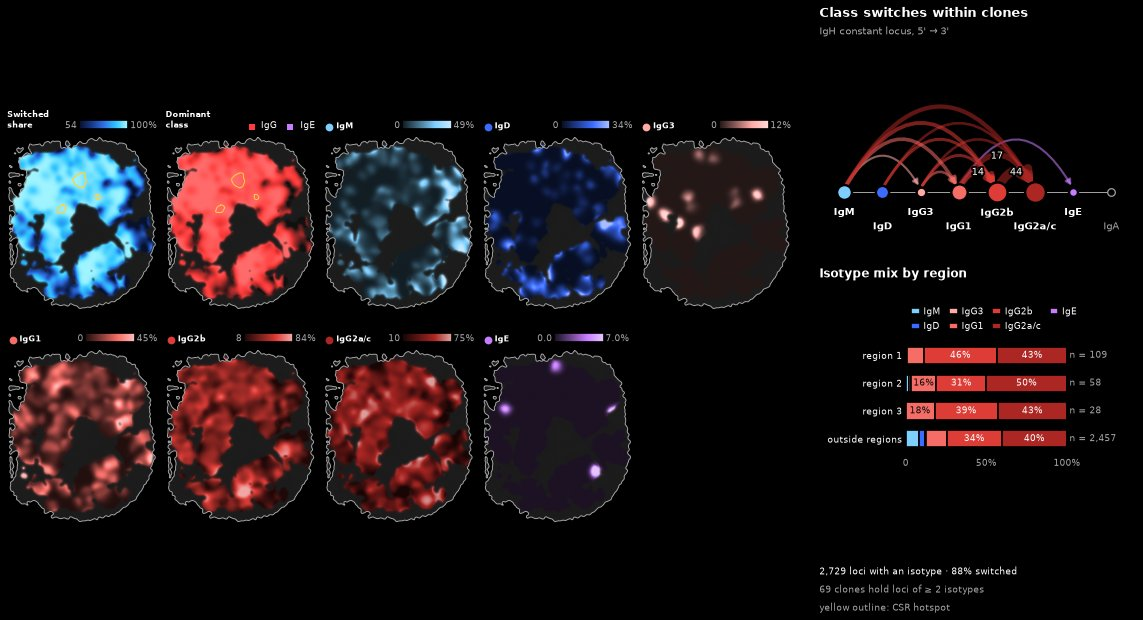

In [24]:
fig = pl.csr_map(hot["D21"], dpi=72)
plt.show()

Heavy-chain loci coloured by isotype class on each node:

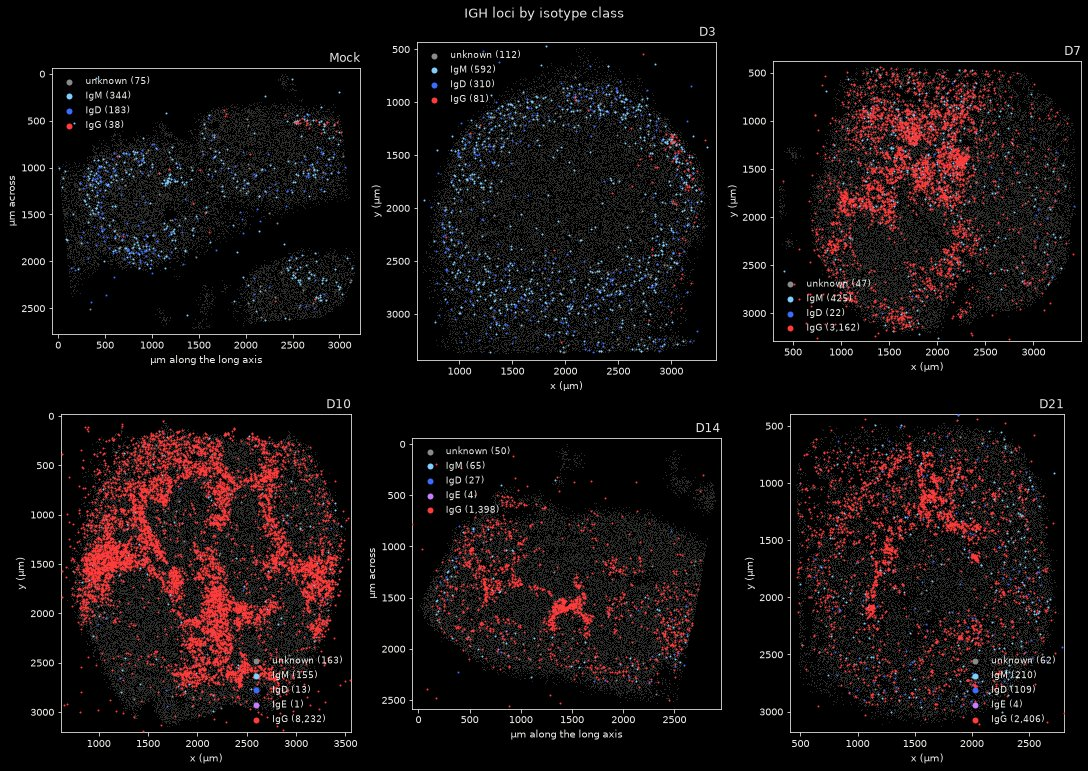

In [25]:
by_day(lambda day, ax: pl.isotype_map(hot[day].loci, isotype_key="isotype_class", background=tissue[day], ax=ax),
       "IGH loci by isotype class")

The switched-share map of each node, with its CSR hotspots outlined:

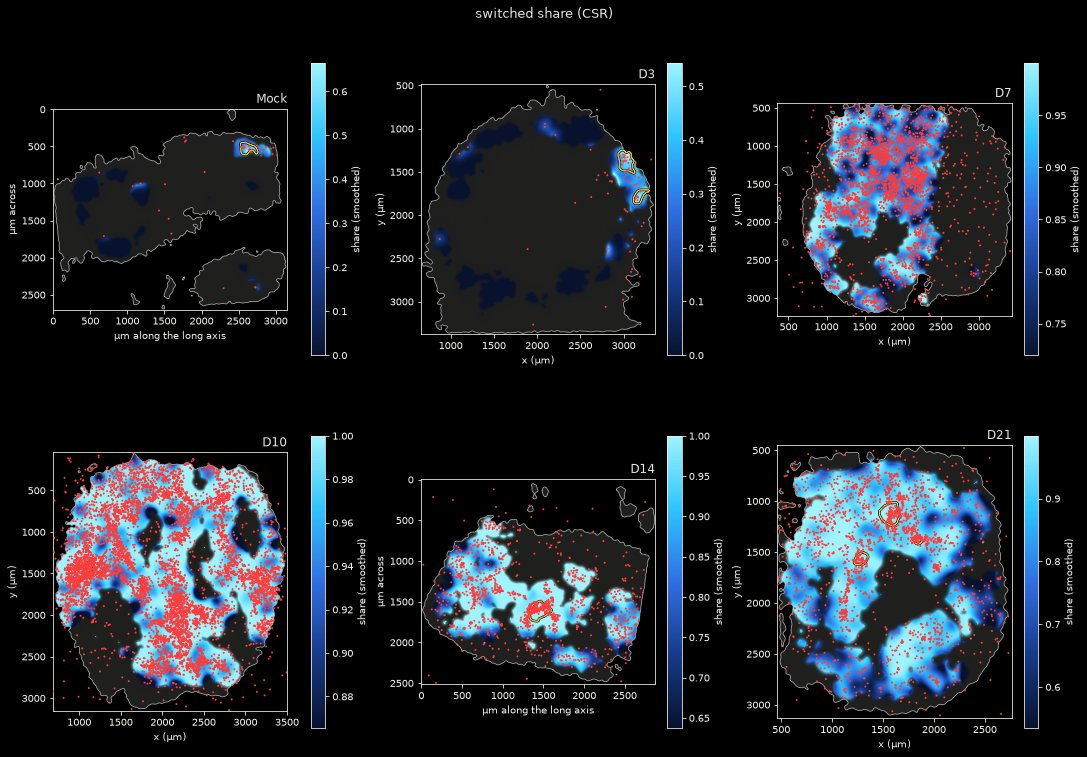

In [26]:
by_day(lambda day, ax: pl.csr_share_map(hot[day].csr, units=hot[day].loci, isotype_key="isotype_class", ax=ax),
       "switched share (CSR)")

The mutated-share map of each node, with its SHM hotspots and the CSR hotspots:

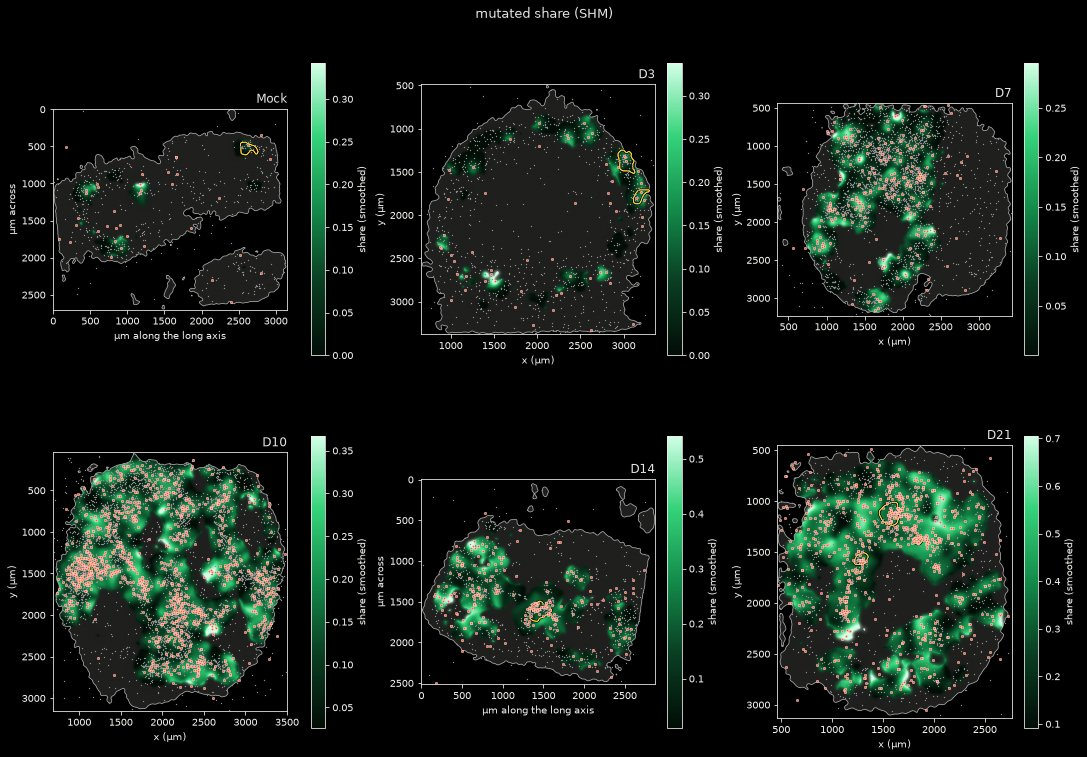

In [27]:
by_day(lambda day, ax: pl.shm_share_map(hot[day].shm, csr=hot[day].csr, units=hot[day].loci, ax=ax),
       "mutated share (SHM)")

## 3. Class-switch potential and its flow on the tissue

`bcr.csr_potential` gives every bead sciCSR's class-switch potential (spatially imputed), `tl.transition_model` biases
each bead's steps towards neighbours of higher potential, and `tl.tpt_flux` tests the flux from the germinal centres
to the plasma-cell area against the potential permuted within regions (100 draws, so the smallest p is 1/101).

In [28]:
flows = {}
for day in DAYS:
    g = regions[day]
    ok = records[day][records[day]["spot_id"].astype(str).isin(g.obs_names)]
    units = bcr.csr_potential(ok, unit_key="spot_id", species="mouse")
    units["region"] = g.obs["region"].astype(str).replace({"nan": "other"}).reindex(units.index).fillna("other").to_numpy()
    model = tl.transition_model(units, time_key="csr_pot", graph="spatial", states="region", rng=0)
    flows[day] = (model, tl.tpt_flux(model, source="GC", target="ASC", rng=0))
pd.DataFrame({day: {k: flux.summary[k] for k in ("rate", "rate_null_mean", "rate_z", "rate_p_value")}
              for day, (model, flux) in flows.items()}).T

,rate,rate_null_mean,rate_z,rate_p_value
Mock,0.004455,0.004413,0.822806,0.188119
D3,0.029356,0.029451,-0.516912,0.702970
D7,0.003733,0.003325,3.409813,0.009901
D10,0.023238,0.023506,-0.384823,0.663366
D14,0.010127,0.008153,4.375914,0.009901
D21,0.037757,0.029783,5.552899,0.009901


The class-switch potential of every bead and the flow of the chain as streamlines:

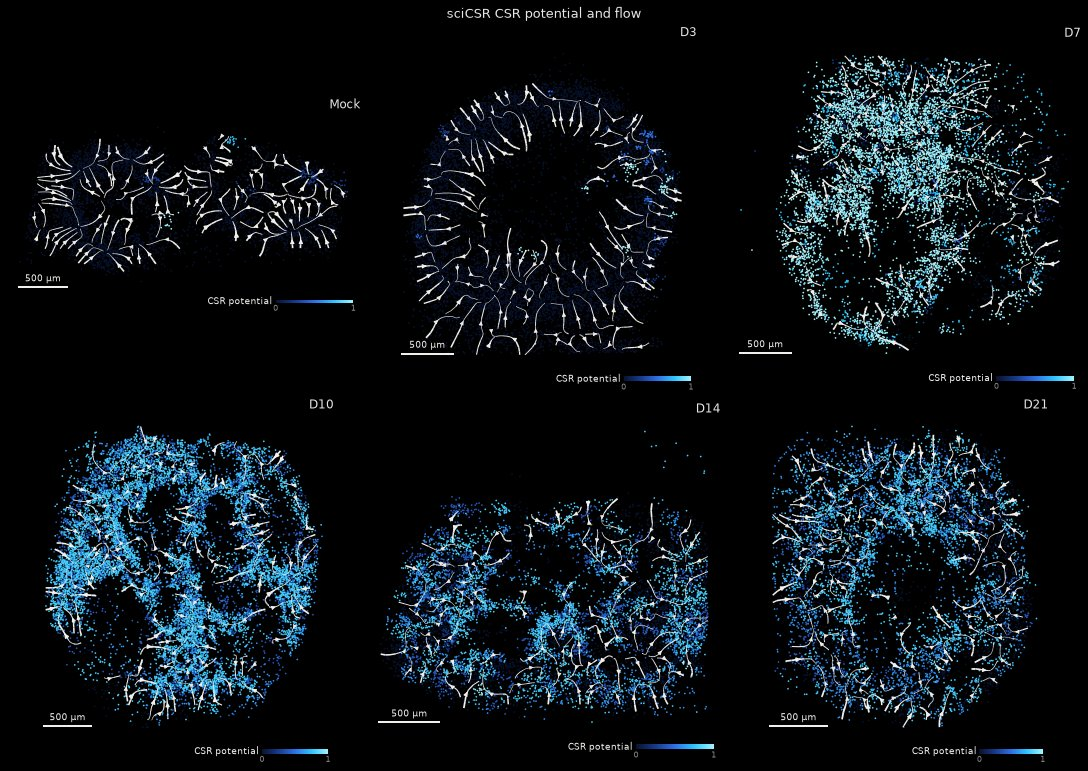

In [29]:
by_day(lambda day, ax: pl.csr_flow(flows[day][0], label="CSR potential", ax=ax), "sciCSR CSR potential and flow")

The net flux between regions, as a bubble matrix:

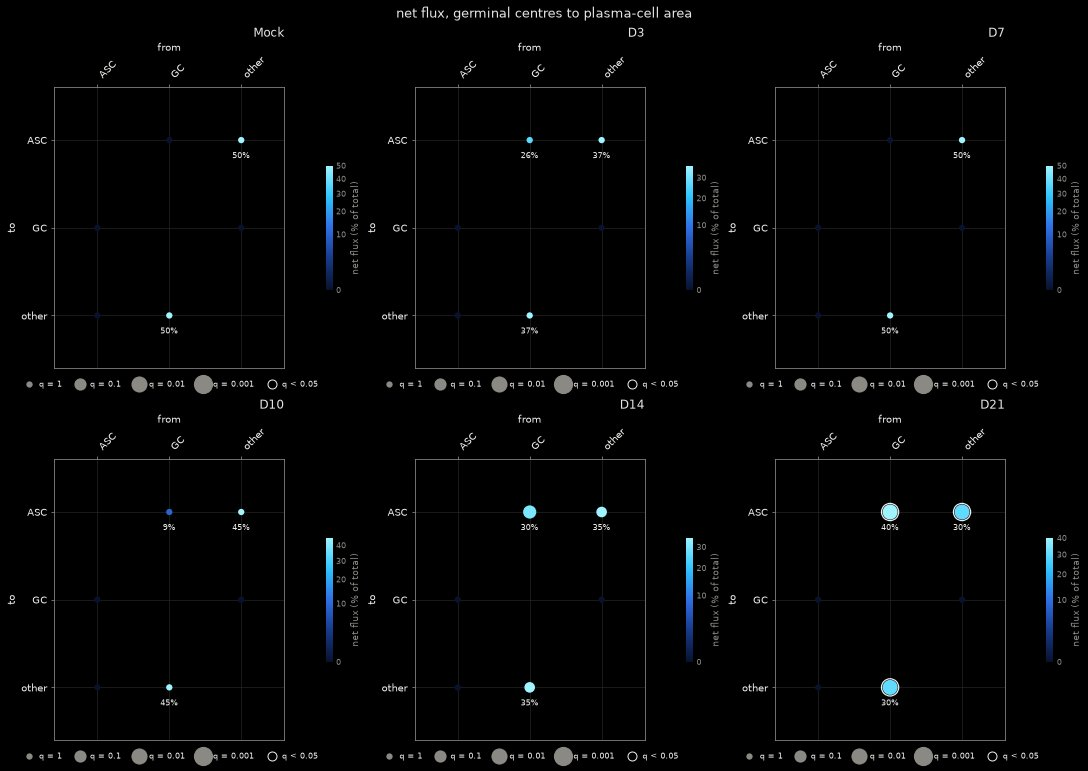

In [30]:
by_day(lambda day, ax: pl.flux_matrix(flows[day][1], value="net", ax=ax), "net flux, germinal centres to plasma-cell area")

## 4. Regions, clones and the scirpy maps

Germinal centres and plasma-cell area called from the transcriptome of each node:

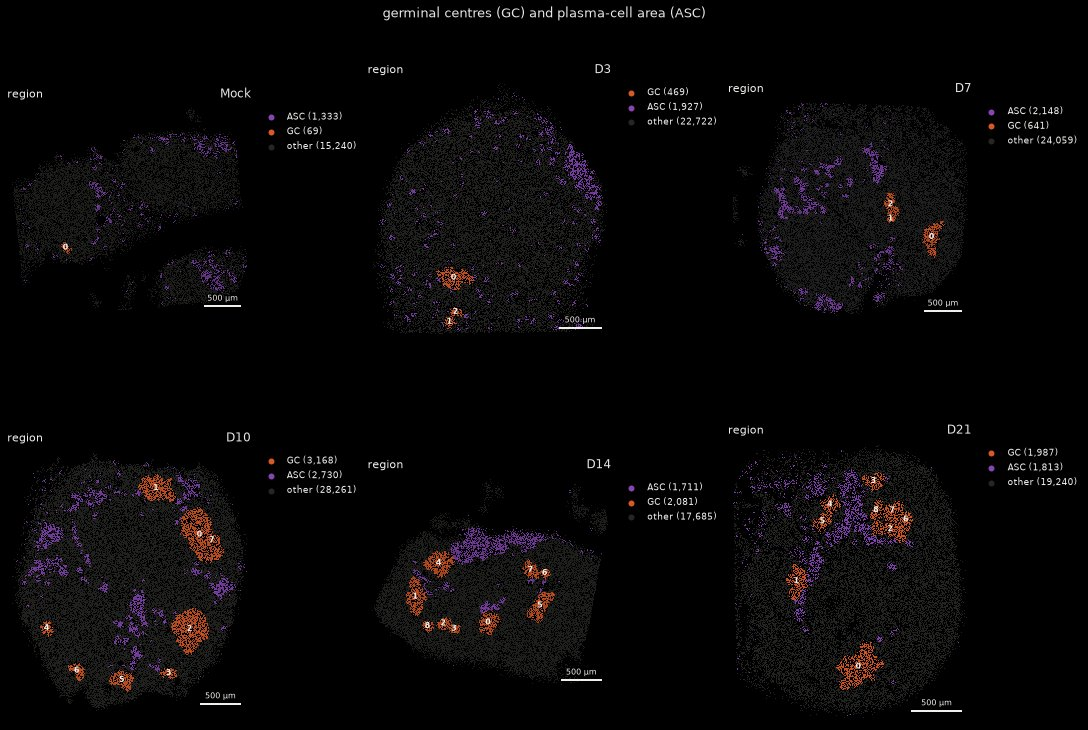

In [31]:
by_day(lambda day, ax: pl.gex_regions(regions[day], ax=ax), "germinal centres (GC) and plasma-cell area (ASC)")

The three largest heavy-chain clones of each node, each linked by its minimum spanning tree:

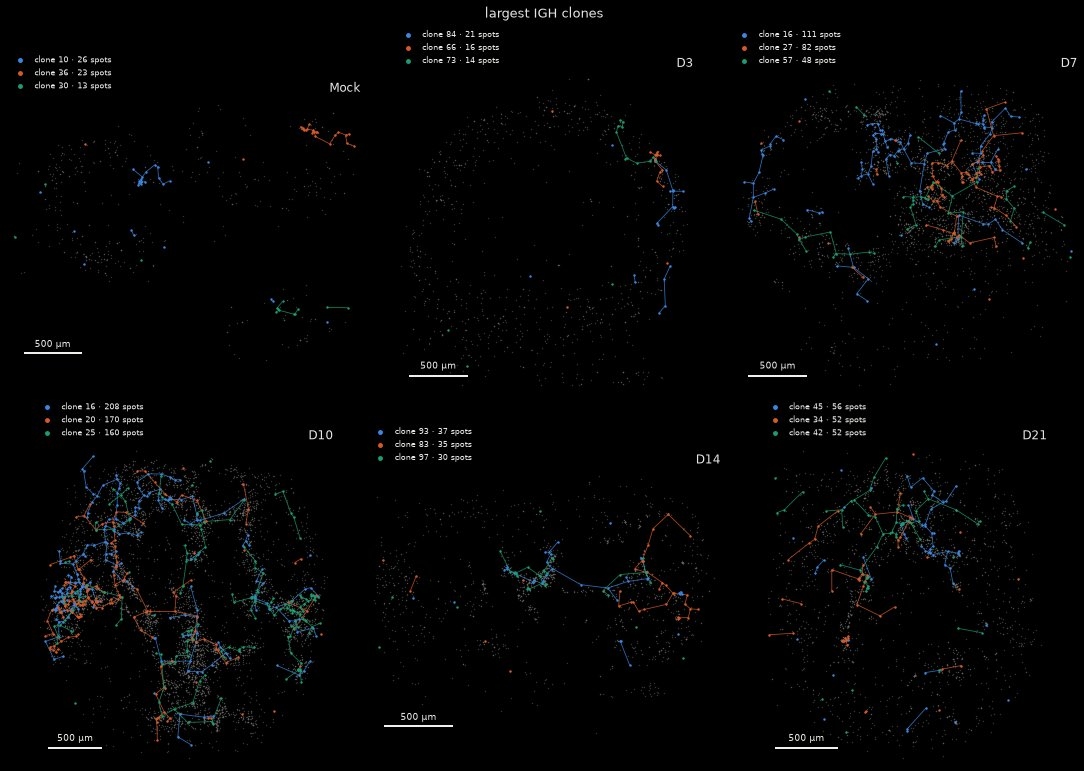

In [32]:
by_day(lambda day, ax: pl.clone_map(records[day][records[day]["locus"] == "IGH"], ax=ax), "largest IGH clones")

scirpy clonotypes (CDR3 Hamming distance 1) back on each node, the five largest highlighted:

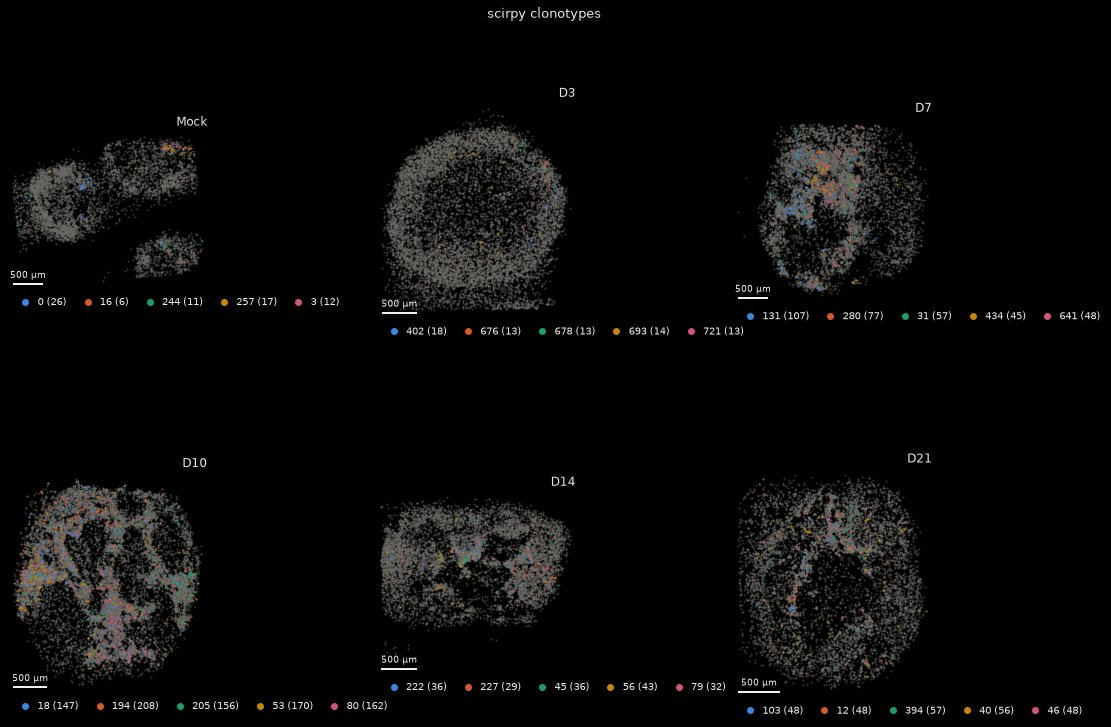

In [33]:
clonotypes = {day: sx.clonotypes(records[day], metric="hamming", cutoff=1) for day in DAYS}
by_day(lambda day, ax: clonotypes[day].plot(highlight=clonotypes[day].table["clonotype"].head(5), ax=ax, size=4),
       "scirpy clonotypes")

The smoothed share of units in expanded clones on each node:

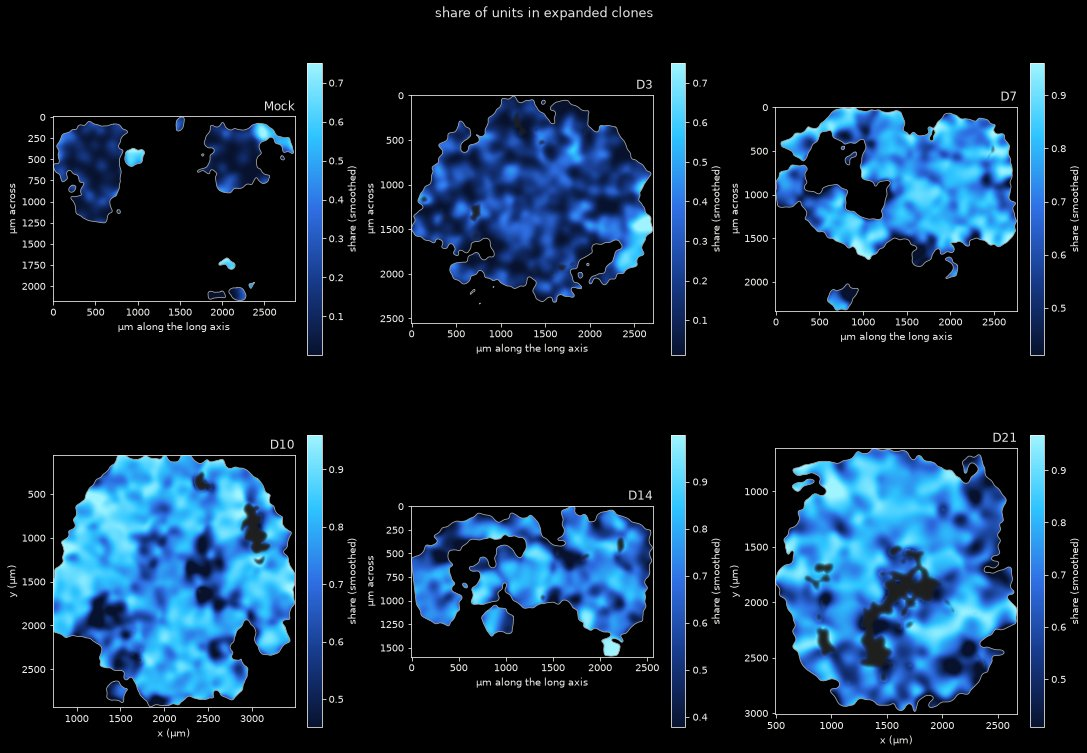

In [34]:
by_day(lambda day, ax: sx.expansion_map(records[day]).plot(ax=ax), "share of units in expanded clones")

## 5. The repertoire across the six days

The heavy-chain molecules of the six nodes in one table, one group per day:

In [35]:
igh = pd.concat([records[day][records[day]["locus"] == "IGH"] for day in DAYS], ignore_index=True)
igh["day"] = pd.Categorical(igh["library_id"], categories=DAYS, ordered=True)
igh.groupby("day", observed=True)["clone_id"].agg(molecules="size", clones="nunique")

,molecules,clones
day,,
Mock,568,349
D3,1001,713
D7,3246,940
D10,7481,1636
D14,1791,482
D21,2542,772


Clone richness and the Gini coefficient of clone sizes per day, rarefied to the smallest day:

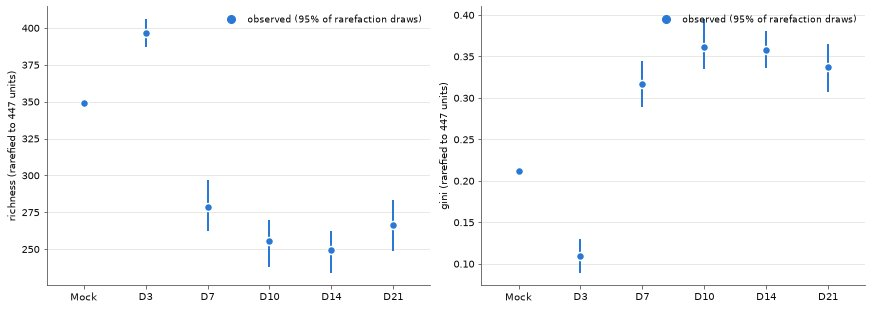

In [36]:
div = tl.diversity(igh, by="day", rng=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
pl.diversity(div, metric="richness", ax=axes[0])
pl.diversity(div, metric="gini", ax=axes[1])
plt.show()

Repertoire overlap between every pair of days:

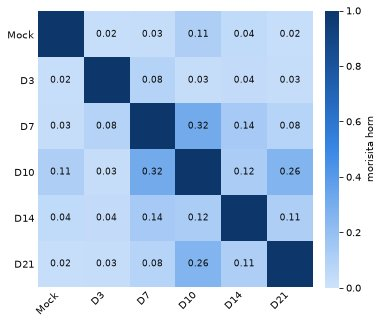

In [37]:
ax = pl.overlap(tl.overlap(igh, by="day"))
plt.show()

The share of loci in each clone-size class, per day:

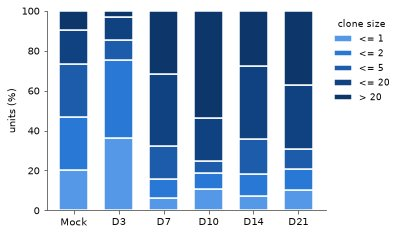

In [38]:
ax = pl.clonal_expansion(tl.clonal_expansion(igh, by="day"))
plt.show()

## 6. Threadfin clone states

`ext.threadfin.run` profiles the transcriptome of each clone's beads (bead types are scored first with the built-in
mouse immune markers, so that the bridge finds its spatial context). Clone states on each node:

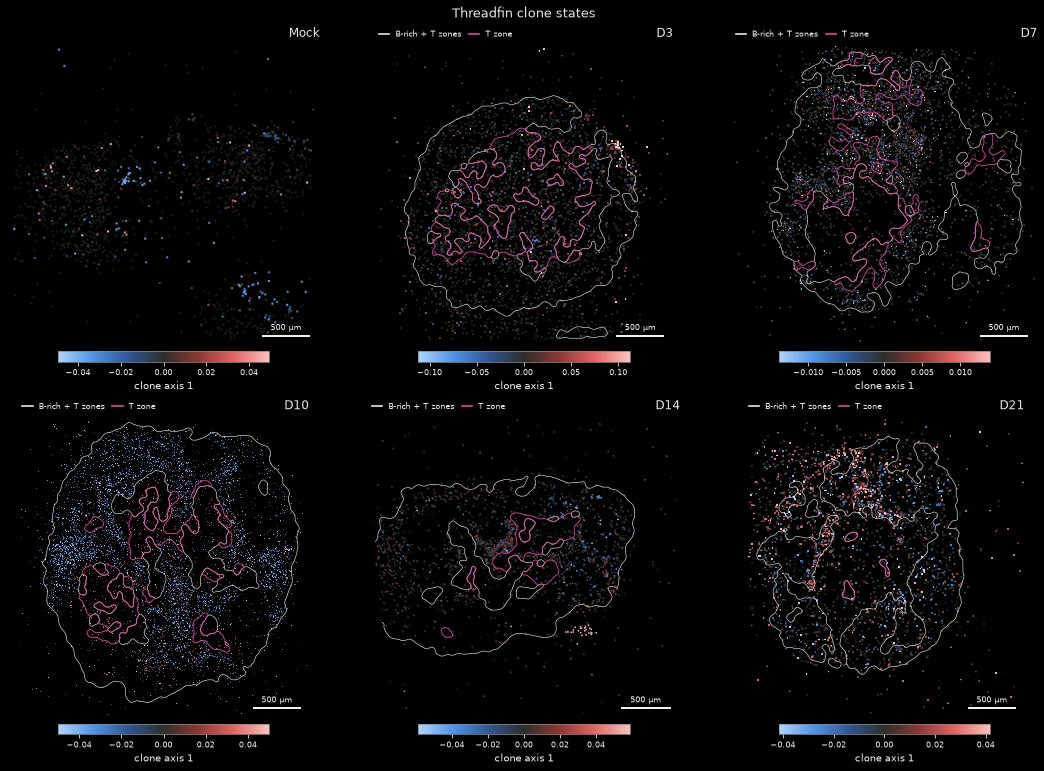

In [39]:
states = {}
for day, sa in data.items():
    g = sa.gex.copy()
    gex.score_cell_types(g, markers="immune_mouse")
    states[day] = threadfin.run(io.SpatialAIR(sa.air, g, sa.meta), rng=0)
by_day(lambda day, ax: pl.clone_state_map(states[day], ax=ax), "Threadfin clone states")

## 7. The key numbers per day

One row per node: the hotspots, the regions with their best clone-level CSR p and the
confirmatory SHM q, the flow test, Threadfin's clone-identity ICC and the trust verdicts.

In [40]:
def value(h, step, item):
    s = h.summary()
    v = s.loc[(s["step"] == step) & (s["item"] == item), "value"]
    return v.iloc[0] if len(v) else np.nan


rows = {}
for day in DAYS:
    h, reg = hot[day], hot[day].regions
    ts = states[day].summary()
    rows[day] = {
        "IGH loci": len(h.loci),
        "CSR hotspots": value(h, "CSR", "hotspots"),
        "SHM hotspots": value(h, "SHM raw", "hotspots"),
        "regions": len(reg),
        "region source": ", ".join(sorted(reg["source"].astype(str).unique())) if "source" in reg and len(reg) else "",
        "best clone-level CSR p": reg["csr_clone_p"].min() if len(reg) else np.nan,
        "best SHM q (confirmatory)": reg["shm_clone_q"].min() if "shm_clone_q" in reg and len(reg) else np.nan,
        "flow p (GC to ASC)": flows[day][1].summary["rate_p_value"],
        "Threadfin ICC": ts.get("icc"),
        "ICC p": ts.get("icc_p"),
        "trust, molecule level": reports[day].status["molecule"],
        "trust, clone level": reports[day].status["clone"],
    }
pd.DataFrame(rows).T

,IGH loci,CSR hotspots,SHM hotspots,regions,region source,best clone-level CSR p,best SHM q (confirmatory),flow p (GC to ASC),Threadfin ICC,ICC p,"trust, molecule level","trust, clone level"
Mock,640,1,0,1,csr,0.996004,0.665433,0.188119,0.017419,0.676617,not tested,signal
D3,1095,2,0,2,csr,0.34965,0.940606,0.70297,0.0351,0.044776,not tested,signal
D7,3656,0,0,0,,NaN,NaN,0.009901,0.017323,0.049751,not tested,signal
D10,8564,1,0,1,csr,0.010989,0.350465,0.663366,0.030653,0.004975,not tested,signal
D14,1544,1,0,1,csr,0.000999,0.80142,0.009901,0.012879,0.353234,not tested,signal
D21,2791,3,0,3,csr,0.000999,0.30057,0.009901,0.040933,0.00995,not tested,signal
